# Image preprocessing

Turns the raw CUB images into model-ready inputs, based on the decisions in the image EDA (`preprocessing.ipynb`).

Steps:
1. **Resizing** (this notebook so far): letterbox every image to 224x224.

## Setup

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

In [2]:
from pathlib import Path
import sys

# Make imports work whether Jupyter starts in the project root or notebooks/.
project_root = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "src" / "data" / "data_loader.py").is_file()
)
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.data.data_loader import load_cub_dataset

d:\preprocess_dl\from-pixels-to-language\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
train_dataset, test_dataset = load_cub_dataset()
class_names = train_dataset.features["label"].names

print("Training samples:", len(train_dataset))
print("Test samples:", len(test_dataset))

Training samples: 5994
Test samples: 5794


## 1. Resizing: letterbox to 224x224

The images have different sizes and shapes (aspect ratio 0.38 to 3.6), but the model needs one fixed size.

**Decision from the EDA:** letterbox. Resize so the **longest** side is 224, then pad the short side to make a square.

- The bird is never cut off (center cropping cut the White-necked Raven's head).
- The bird is never distorted (stretching distorts 76% of images by more than 25%).
- Padding uses the ImageNet mean color, which becomes about 0 after normalization, so it carries no information.

**Why 224:** the pretrained models were trained at 224x224, it divides evenly through the CNN's 32x downsampling (7x7 final feature map), and it keeps training affordable on a free T4 GPU.

In [4]:
TARGET_SIZE = 224
PAD_COLOR = (124, 116, 104)  # ImageNet mean (0.485, 0.456, 0.406) x 255


def letterbox(img, size=TARGET_SIZE, fill=PAD_COLOR):
    """Resize so the longest side is `size`, then pad to a square. Nothing is cut off."""
    img = img.convert("RGB")  # also turns the grayscale (L) images into 3 channels
    scale = size / max(img.size)
    new_w, new_h = round(img.width * scale), round(img.height * scale)
    resized = img.resize((new_w, new_h), Image.BICUBIC)

    canvas = Image.new("RGB", (size, size), fill)
    canvas.paste(resized, ((size - new_w) // 2, (size - new_h) // 2))  # center it
    return canvas

### Image sizes and shape types

Uses the statistics saved by the image EDA if they exist; otherwise reads only the image sizes (fast, no full decoding).

In [5]:
STATS_PATH = project_root / "outputs" / "eda" / "image_stats.csv"

if STATS_PATH.exists():
    sizes = pd.read_csv(STATS_PATH, usecols=["split", "idx", "label", "width", "height"])
else:
    rows = []
    for split, dataset in [("train", train_dataset), ("test", test_dataset)]:
        for idx, (img, label) in enumerate(zip(dataset["image"], dataset["label"])):
            rows.append({"split": split, "idx": idx, "label": label,
                         "width": img.width, "height": img.height})
    sizes = pd.DataFrame(rows)

sizes["aspect_ratio"] = sizes["width"] / sizes["height"]
sizes["species"] = sizes["label"].map(lambda label: class_names[label])
# Share of the square canvas that becomes padding: 1 - short side / long side
sizes["padding_%"] = (
    1 - sizes[["width", "height"]].min(axis=1) / sizes[["width", "height"]].max(axis=1)
) * 100

SHAPES = [
    ("Tall portrait", 0.0, 0.67),
    ("Portrait", 0.67, 0.95),
    ("Square", 0.95, 1.05),
    ("Landscape", 1.05, 1.4),
    ("Wide landscape", 1.4, 2.0),
    ("Panorama", 2.0, float("inf")),
]
shape_names = [name for name, _, _ in SHAPES]
sizes["shape"] = pd.cut(
    sizes["aspect_ratio"],
    bins=[low for _, low, _ in SHAPES] + [SHAPES[-1][2]],
    labels=shape_names,
    right=False,
)

summary = sizes.groupby("shape", observed=False).agg(
    images=("idx", "size"),
    aspect_min=("aspect_ratio", "min"),
    aspect_max=("aspect_ratio", "max"),
    mean_padding_pct=("padding_%", "mean"),
)
summary["share_%"] = summary["images"] / len(sizes) * 100
display(summary.round(2))

,images,aspect_min,aspect_max,mean_padding_pct,share_%
shape,,,,,
Tall portrait,570,0.38,0.67,34.30,4.84
Portrait,1633,0.67,0.95,21.29,13.85
Square,618,0.95,1.05,1.46,5.24
Landscape,4294,1.05,1.40,21.59,36.43
Wide landscape,4641,1.40,1.98,33.32,39.37
Panorama,32,2.00,3.60,53.96,0.27


### Letterbox examples, one per shape type

Both panels use the same pixel scale (0-500), so the output really looks smaller. The **red square** is the 224x224 output: everything inside it is image or padding; outside it is empty plot area.

In [ ]:
examples = [
    sizes[(sizes["split"] == "train") & (sizes["shape"] == name)].sample(1, random_state=42).iloc[0]
    for name in shape_names
]

fig, axes = plt.subplots(len(examples), 2, figsize=(10, 5 * len(examples)))
for (ax_orig, ax_box), row in zip(axes, examples):
    img = train_dataset[int(row["idx"])]["image"].convert("RGB")
    boxed = letterbox(img)
    scale = TARGET_SIZE / max(img.size)

    ax_orig.imshow(img, extent=(0, img.width, img.height, 0))
    ax_orig.set_title(f"{row['shape']}: original {img.width}x{img.height} "
                      f"(aspect {row['aspect_ratio']:.2f})\n{row['species']} (train #{row['idx']})")
    ax_box.imshow(boxed, extent=(0, TARGET_SIZE, TARGET_SIZE, 0))
    ax_box.add_patch(plt.Rectangle((0, 0), TARGET_SIZE, TARGET_SIZE,
                                   fill=False, edgecolor="red", linewidth=2))
    ax_box.set_title(f"Letterbox {TARGET_SIZE}x{TARGET_SIZE} "
                     f"(scale x{scale:.2f}, padding {row['padding_%']:.0f}%)")

    for ax in (ax_orig, ax_box):
        ax.set_xlim(0, 500)
        ax.set_ylim(500, 0)
        ax.set_xlabel("pixels")

plt.tight_layout()
plt.show()

### Check: every image comes out the same size

Runs the letterbox on every image in both splits and checks the output size and color mode.

In [6]:
import time
from collections import Counter

start = time.time()
output_checks = Counter()
for split, dataset in [("train", train_dataset), ("test", test_dataset)]:
    for img in dataset["image"]:
        out = letterbox(img)
        output_checks[(split, out.size, out.mode)] += 1

for (split, size, mode), count in sorted(output_checks.items()):
    print(f"{split}: {count} images -> size {size}, mode {mode}")
print(f"Took {time.time() - start:.0f} s")

assert all(size == (TARGET_SIZE, TARGET_SIZE) and mode == "RGB"
           for _, size, mode in output_checks), "some images have the wrong size or mode"
print("All images are", TARGET_SIZE, "x", TARGET_SIZE, "RGB")

test: 5794 images -> size (224, 224), mode RGB
train: 5994 images -> size (224, 224), mode RGB
Took 37 s
All images are 224 x 224 RGB


find all the gray scale image

In [7]:
def is_gray_rgb(img, tolerance=5):
    """True if an RGB image is really grayscale: R, G and B (almost) equal everywhere."""
    small = np.asarray(img.convert("RGB").resize((64, 64)), dtype=np.int16)
    diff = max(np.abs(small[..., 0] - small[..., 1]).max(),
               np.abs(small[..., 1] - small[..., 2]).max())
    return diff < tolerance


# Find every grayscale image: stored with 1 channel (mode "L"), or stored as RGB with R = G = B
gray_rows = []
for split, dataset in [("train", train_dataset), ("test", test_dataset)]:
    labels = dataset["label"]
    for idx, img in enumerate(dataset["image"]):
        if img.mode != "RGB" or is_gray_rgb(img):
            gray_rows.append({
                "split": split,
                "idx": idx,
                "mode": img.mode,
                "size": img.size,
                "species": class_names[labels[idx]],
            })

gray_images = pd.DataFrame(gray_rows)
print("Grayscale images found:", len(gray_images))
display(gray_images)


Grayscale images found: 9


,split,idx,mode,size,species
0,train,726,L,"(500, 375)",Pelagic Cormorant
1,train,1743,RGB,"(500, 375)",California Gull
2,train,1868,L,"(500, 326)",Ivory Gull
3,train,1950,L,"(500, 281)",Western Gull
4,train,2764,L,"(500, 500)",Clark Nutcracker
5,test,193,L,"(500, 333)",Brewer Blackbird
6,test,1764,L,"(500, 398)",Ivory Gull
7,test,2472,L,"(485, 500)",Mallard
8,test,3082,L,"(484, 500)",White necked Raven


train #726: mode L -> RGB, array shape (375, 500) -> (375, 500, 3)
train #1743: mode RGB -> RGB, array shape (375, 500, 3) -> (375, 500, 3)
train #1868: mode L -> RGB, array shape (326, 500) -> (326, 500, 3)
train #1950: mode L -> RGB, array shape (281, 500) -> (281, 500, 3)
train #2764: mode L -> RGB, array shape (500, 500) -> (500, 500, 3)
test #193: mode L -> RGB, array shape (333, 500) -> (333, 500, 3)
test #1764: mode L -> RGB, array shape (398, 500) -> (398, 500, 3)
test #2472: mode L -> RGB, array shape (500, 485) -> (500, 485, 3)
test #3082: mode L -> RGB, array shape (500, 484) -> (500, 484, 3)


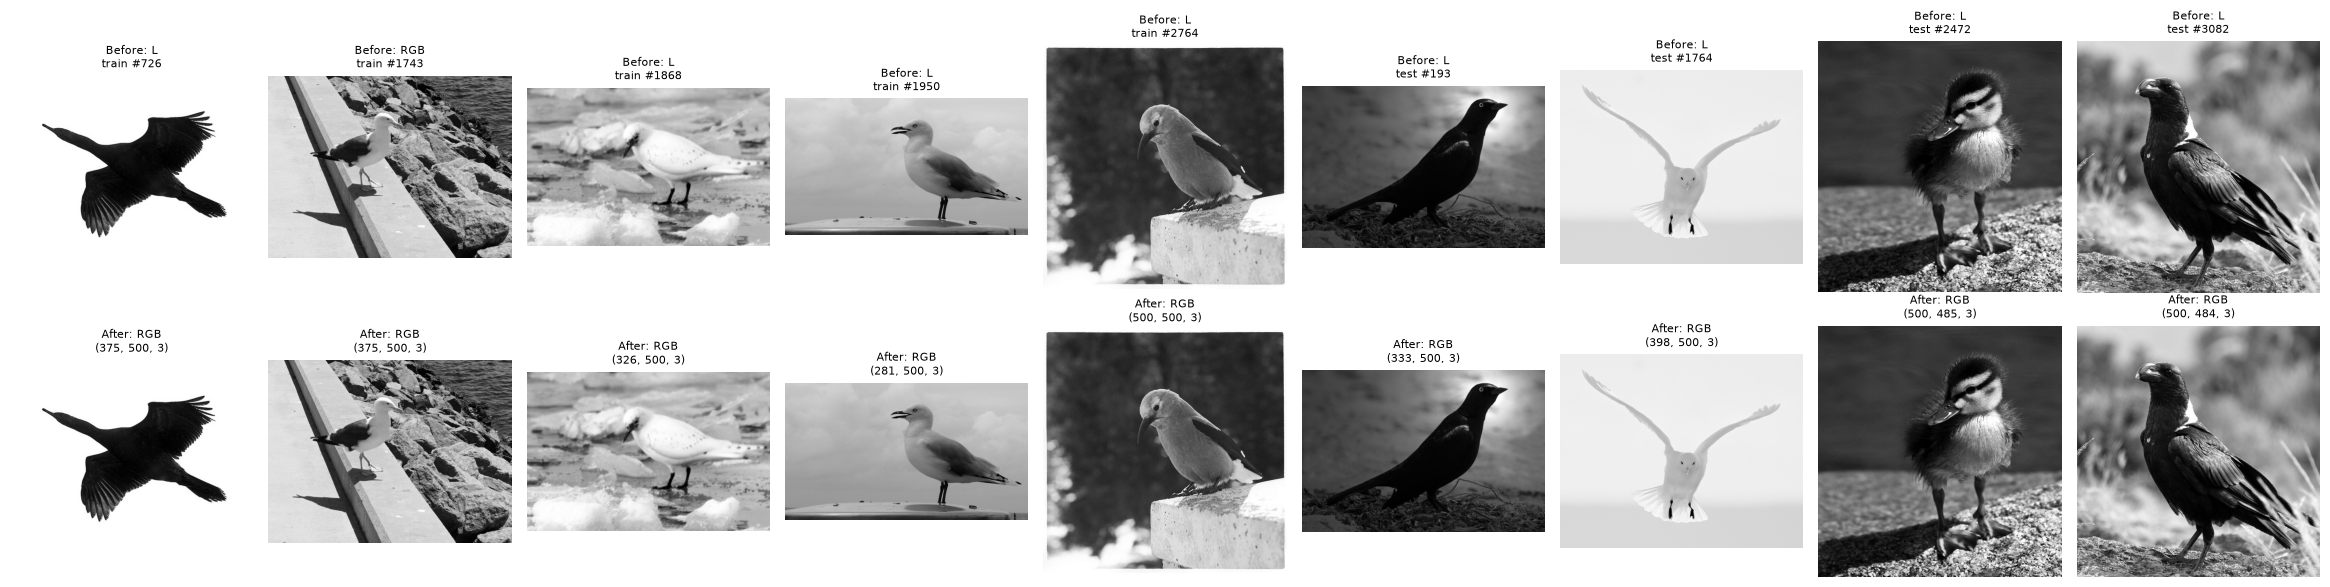

All grayscale images converted to 3-channel RGB


In [8]:
def to_rgb(img):
    """Convert any image to 3-channel RGB. A grayscale value g becomes (g, g, g)."""
    return img if img.mode == "RGB" else img.convert("RGB")


# Convert each grayscale image and compare before / after
fig, axes = plt.subplots(2, len(gray_images), figsize=(2.6 * len(gray_images), 6), squeeze=False)
for col, row in enumerate(gray_images.itertuples(index=False)):
    dataset = train_dataset if row.split == "train" else test_dataset
    original = dataset[row.idx]["image"]
    converted = to_rgb(original)

    before = np.asarray(original)
    after = np.asarray(converted)
    print(f"{row.split} #{row.idx}: mode {original.mode} -> {converted.mode}, "
          f"array shape {before.shape} -> {after.shape}")

    axes[0, col].imshow(original, cmap="gray")
    axes[0, col].set_title(f"Before: {original.mode}\n{row.split} #{row.idx}", fontsize=8)
    axes[1, col].imshow(converted)
    axes[1, col].set_title(f"After: {converted.mode}\n{after.shape}", fontsize=8)
    for ax in axes[:, col]:
        ax.axis("off")

plt.tight_layout()
plt.show()

# Check: after conversion every image has 3 channels
for row in gray_images.itertuples(index=False):
    dataset = train_dataset if row.split == "train" else test_dataset
    converted = np.asarray(to_rgb(dataset[row.idx]["image"]))
    assert converted.ndim == 3 and converted.shape[2] == 3, f"{row.split} #{row.idx} is not RGB"
print("All grayscale images converted to 3-channel RGB")


## 3. Remove duplicate images

The image EDA found near-identical photos with a perceptual hash (dHash): images that look the same get the same 64-bit value, even at a different size.

Rules:
- **Train/test duplicates are data leakage**: the model would be tested on a photo it trained on. Remove the **training** copy.
- **Duplicates inside train**: keep the first copy, remove the others, so the same photo cannot end up in both train and validation later.
- **The test set is never changed**, so results stay comparable with published results on the full test set.

In [9]:
def dhash(img, size=8):
    """Perceptual hash: near-identical images get the same 64-bit value (same as the EDA)."""
    gray = img.convert("L").resize((size + 1, size), Image.BILINEAR)
    pixels = np.asarray(gray, dtype=np.int16)
    bits = (pixels[:, 1:] > pixels[:, :-1]).flatten()
    return f"{int(''.join('1' if b else '0' for b in bits), 2):016x}"


# Reuse the hashes saved by the image EDA if they exist; otherwise compute them (~1 minute)
if STATS_PATH.exists():
    hashes = pd.read_csv(STATS_PATH, usecols=["split", "idx", "label", "dhash"], dtype={"dhash": str})
else:
    rows = []
    for split, dataset in [("train", train_dataset), ("test", test_dataset)]:
        for idx, (img, label) in enumerate(zip(dataset["image"], dataset["label"])):
            rows.append({"split": split, "idx": idx, "label": label, "dhash": dhash(img)})
    hashes = pd.DataFrame(rows)

hashes["species"] = hashes["label"].map(lambda label: class_names[label])

duplicates = hashes[hashes.duplicated("dhash", keep=False)].sort_values(["dhash", "split", "idx"])
groups = duplicates.groupby("dhash")["split"].agg(list)

print("Duplicate groups:", len(groups))
print("Groups shared by train and test (leakage):", groups.map(lambda s: len(set(s)) > 1).sum())
display(duplicates[["dhash", "split", "idx", "species"]])

Duplicate groups: 6
Groups shared by train and test (leakage): 2


,dhash,split,idx,species
9258,56767a5ad2c4648c,test,3264,Brewer Sparrow
9270,56767a5ad2c4648c,test,3276,Brewer Sparrow
8362,5c5c7cfc1c131f1b,test,2368,Red legged Kittiwake
8368,5c5c7cfc1c131f1b,test,2374,Red legged Kittiwake
5315,723218d94d952c0a,train,5315,Swainson Warbler
5333,723218d94d952c0a,train,5333,Swainson Warbler
11109,734361e0b0342787,test,5115,Prothonotary Warbler
5277,734361e0b0342787,train,5277,Prothonotary Warbler
6655,b4a64e8e8e0d5c5b,test,661,Bronzed Cowbird
774,b4a64e8e8e0d5c5b,train,774,Bronzed Cowbird


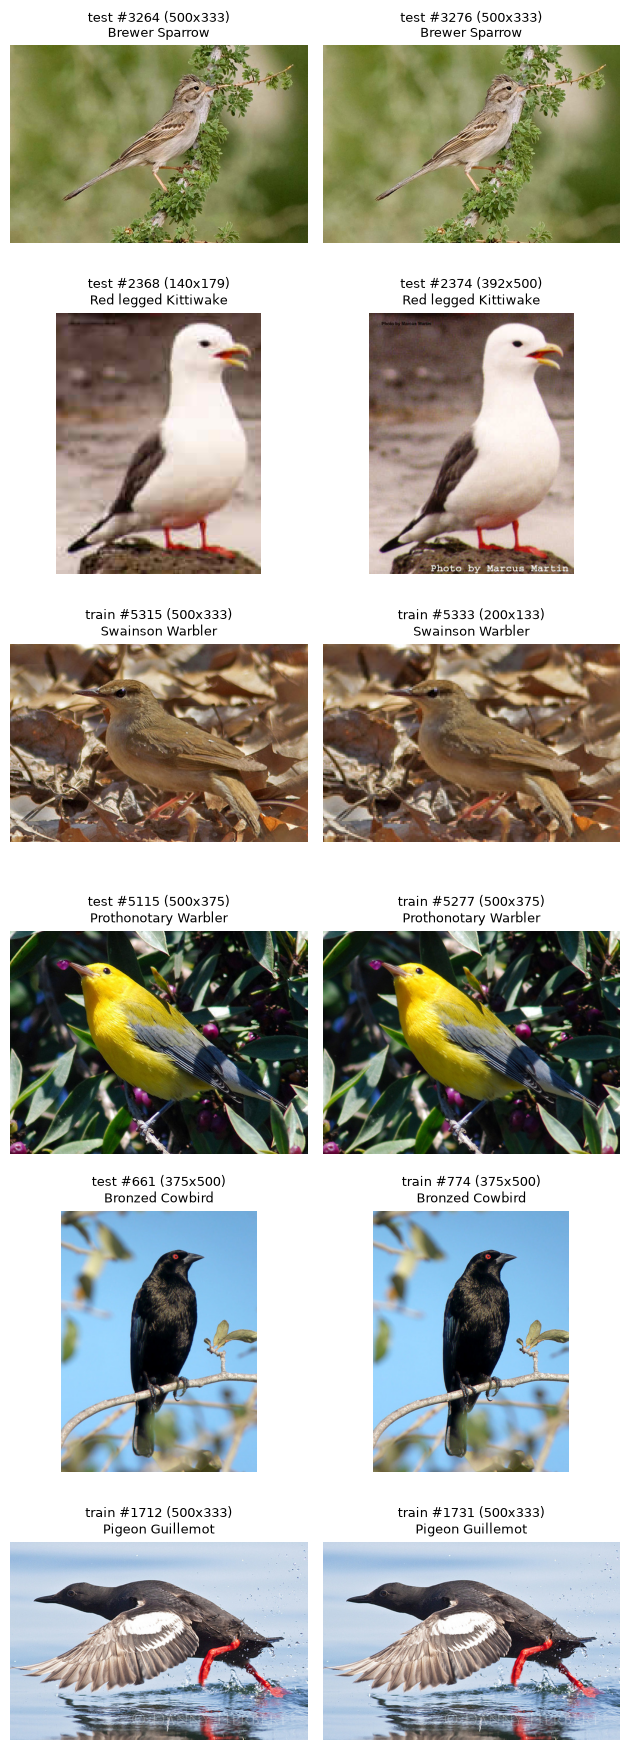

In [10]:
# Look at each group side by side to confirm they really are the same photo
group_list = list(duplicates.groupby("dhash"))
ncols = max(len(group) for _, group in group_list)

fig, axes = plt.subplots(len(group_list), ncols, figsize=(3.2 * ncols, 3 * len(group_list)), squeeze=False)
for row_axes, (dhash_value, group) in zip(axes, group_list):
    for ax in row_axes:
        ax.axis("off")
    for ax, row in zip(row_axes, group.itertuples(index=False)):
        dataset = train_dataset if row.split == "train" else test_dataset
        img = dataset[int(row.idx)]["image"]
        ax.imshow(img.convert("RGB"))
        ax.set_title(f"{row.split} #{row.idx} ({img.width}x{img.height})\n{row.species}", fontsize=9)

plt.tight_layout()
plt.show()

In [11]:
import json

train_hashes = hashes[hashes["split"] == "train"]
test_hash_to_idx = (
    hashes[hashes["split"] == "test"].groupby("dhash")["idx"].apply(list).to_dict()
)

leaks_test = train_hashes["dhash"].isin(test_hash_to_idx)
repeated_in_train = train_hashes.duplicated("dhash", keep="first")

removed = train_hashes[leaks_test | repeated_in_train].copy()
removed["reason"] = [
    "same photo as test " + ", ".join(f"#{i}" for i in test_hash_to_idx[h]) if h in test_hash_to_idx
    else "second copy of a training image"
    for h in removed["dhash"]
]

removed_idx = set(removed["idx"])
keep_idx = [i for i in range(len(train_dataset)) if i not in removed_idx]
train_clean = train_dataset.select(keep_idx)

print("Training images before:", len(train_dataset))
print("Removed:", len(removed),
      f"({int(leaks_test.sum())} duplicates of test images, "
      f"{int((repeated_in_train & ~leaks_test).sum())} repeated within train)")
print("Training images after:", len(train_clean))
print("Test images (unchanged):", len(test_dataset))
display(removed[["idx", "species", "reason"]])

# Save the removed indices so the training code uses exactly the same cleaned set
REMOVED_PATH = project_root / "outputs" / "preprocessing" / "removed_train_duplicates.json"
REMOVED_PATH.parent.mkdir(parents=True, exist_ok=True)
REMOVED_PATH.write_text(json.dumps(
    [{"idx": int(r.idx), "species": r.species, "reason": r.reason} for r in removed.itertuples()],
    indent=2,
))
print("Saved to", REMOVED_PATH)

Training images before: 5994
Removed: 4 (2 duplicates of test images, 2 repeated within train)
Training images after: 5990
Test images (unchanged): 5794


,idx,species,reason
774,774,Bronzed Cowbird,same photo as test #661
1731,1731,Pigeon Guillemot,second copy of a training image
5277,5277,Prothonotary Warbler,same photo as test #5115
5333,5333,Swainson Warbler,second copy of a training image


Saved to d:\preprocess_dl\from-pixels-to-language\outputs\preprocessing\removed_train_duplicates.json


In [12]:
# Check: no duplicates left inside train, and no training image matches a test image
clean_hashes = train_hashes[train_hashes["idx"].isin(keep_idx)]

assert not clean_hashes["dhash"].duplicated().any(), "duplicates left inside train"
assert not clean_hashes["dhash"].isin(test_hash_to_idx).any(), "training images still match test images"
assert len(train_clean) == len(train_dataset) - len(removed)
print("No duplicates left in train, and no overlap with test")

within_test = hashes[hashes["split"] == "test"]["dhash"].duplicated(keep=False).sum()
print(f"Note: {within_test} test images belong to duplicate pairs inside test; the test set is left unchanged.")

No duplicates left in train, and no overlap with test
Note: 4 test images belong to duplicate pairs inside test; the test set is left unchanged.


## 4. Augmentation (training images only)

With only ~30 training images per species, the model can memorize the photos instead of learning the species (overfitting). Augmentation gives it a **new random version of each photo every time it is loaded** (online augmentation), so over 30 epochs it sees 30 different versions of every photo, without storing any extra files.

It teaches the model that these changes **do not change the species**:

| Step | Setting | Why |
|---|---|---|
| Brightness / contrast | ±20% | Lighting differs between photos |
| Saturation | ±10% | Camera differences; kept mild because color matters |
| Letterbox to 224 | | The whole bird is always in the image |
| Horizontal flip | 50% chance | A bird facing left is the same species |
| Rotation | ±15° | Camera tilt |
| Shift | ±5% | Bird position in the frame |
| Zoom | 0.9-1.1x | Distance to the bird; small, so the bird stays in frame |
| No hue change | | Color identifies species: hue shifts could turn one species into another |
| No vertical flip | | Upside-down birds do not occur in real photos |
| No random crop | | It can cut off the bird |

**Order:** color changes happen **before** the letterbox, so the padding keeps exactly the ImageNet mean color. Rotation and shifts happen **after**, and the empty corners they create are filled with the same padding color.

**Validation and test images are never augmented**: they only get the letterbox, so their scores are repeatable.

In [13]:
import torch
from torchvision.transforms import v2 as T

# Color changes: applied to the original photo, before the letterbox
color_augment = T.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.1)

# Geometric changes: applied after the letterbox; empty corners get the padding color
geometric_augment = T.Compose([
    T.RandomHorizontalFlip(p=0.5),
    T.RandomAffine(degrees=15, translate=(0.05, 0.05), scale=(0.9, 1.1), fill=PAD_COLOR),
])


def train_transform(img):
    """Training images: random color change -> letterbox -> random flip/rotation/shift/zoom."""
    img = to_rgb(img)
    img = color_augment(img)
    img = letterbox(img)
    return geometric_augment(img)


def eval_transform(img):
    """Validation / test images: letterbox only, no randomness."""
    return letterbox(to_rgb(img))

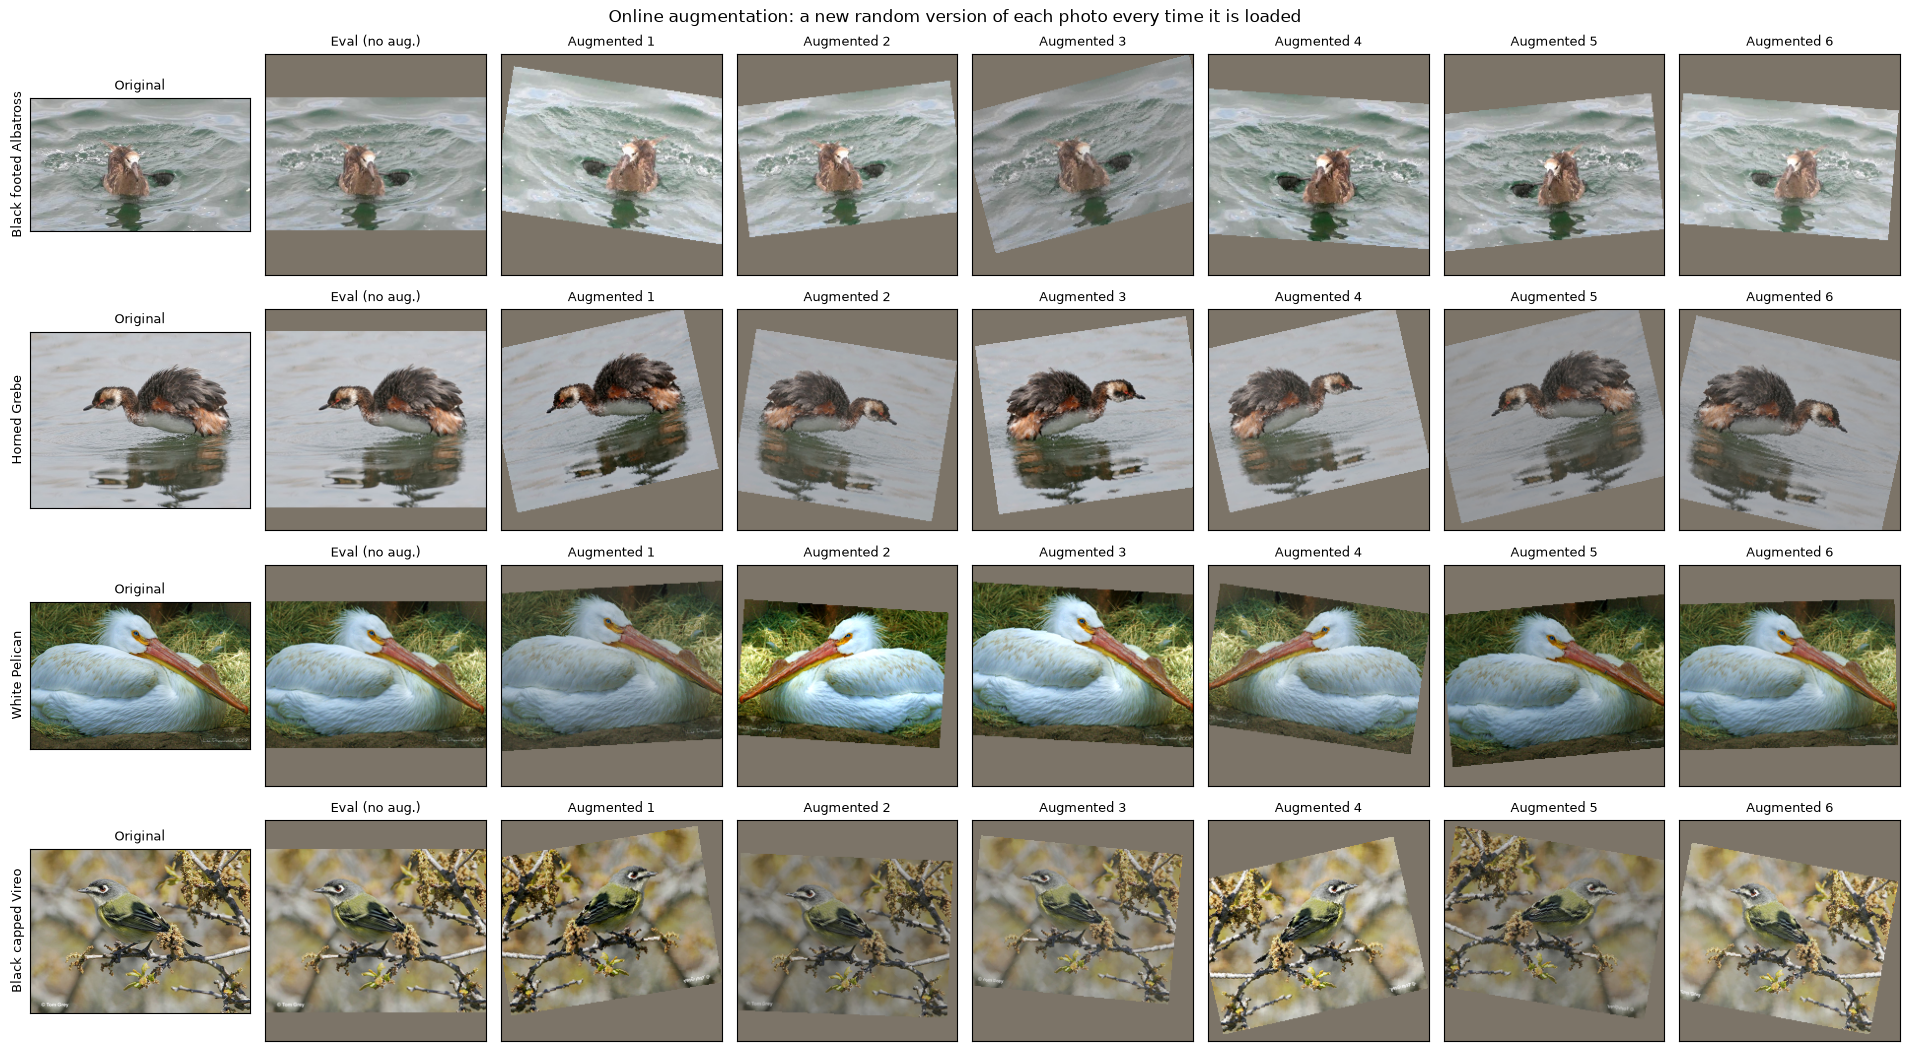

In [14]:
# The same photos, augmented several times: every call gives a different version
torch.manual_seed(42)  # fixed seed so this figure looks the same every run
example_idx = [0, 1500, 3000, 4500]  # positions in train_clean, spread across species
n_augmented = 6

fig, axes = plt.subplots(len(example_idx), n_augmented + 2,
                         figsize=(2.4 * (n_augmented + 2), 2.7 * len(example_idx)))
for row_axes, idx in zip(axes, example_idx):
    sample = train_clean[idx]
    img = sample["image"]

    views = [("Original", img.convert("RGB")), ("Eval (no aug.)", eval_transform(img))]
    views += [(f"Augmented {k + 1}", train_transform(img)) for k in range(n_augmented)]
    for ax, (title, view) in zip(row_axes, views):
        ax.imshow(view)
        ax.set_title(title, fontsize=9)
        ax.set_xticks([])
        ax.set_yticks([])
    row_axes[0].set_ylabel(class_names[sample["label"]], fontsize=9)

fig.suptitle("Online augmentation: a new random version of each photo every time it is loaded")
plt.tight_layout()
plt.show()

In [15]:
# Checks on 200 random training images
rng = np.random.default_rng(42)
check_idx = rng.choice(len(train_clean), size=200, replace=False)

for idx in check_idx:
    img = train_clean[int(idx)]["image"]
    out = train_transform(img)
    assert out.size == (TARGET_SIZE, TARGET_SIZE) and out.mode == "RGB", f"wrong output for #{idx}"
print(f"All {len(check_idx)} augmented images are {TARGET_SIZE}x{TARGET_SIZE} RGB")

# Training transform is random, evaluation transform is not
img = train_clean[0]["image"]
train_differs = not np.array_equal(np.asarray(train_transform(img)), np.asarray(train_transform(img)))
eval_same = np.array_equal(np.asarray(eval_transform(img)), np.asarray(eval_transform(img)))
print("Training transform gives a different image each call:", train_differs)
print("Evaluation transform gives the same image each call:", eval_same)

All 200 augmented images are 224x224 RGB
Training transform gives a different image each call: True
Evaluation transform gives the same image each call: True


## 5. Normalization (every split)

The last step turns each 224x224 image into a **tensor** (the format the model takes) and rescales its values:

1. **Scale to 0-1**: divide every pixel value (0-255) by 255.
2. **Standardize each channel**: `(value - mean) / std`, using the ImageNet values.

| Channel | mean | std |
|---|---|---|
| R | 0.485 | 0.229 |
| G | 0.456 | 0.224 |
| B | 0.406 | 0.225 |

Why:
- **Pretrained models expect it**: they were trained on images normalized with exactly these values.
- **Stable training**: inputs centered around 0 with similar scales keep gradients well-behaved, for the from-scratch CNN too.
- **The padding becomes 0**: the padding color (124, 116, 104) is the ImageNet mean x 255, so after normalization it is about 0 and carries no information.
- **ImageNet instead of CUB's own statistics**: the EDA measured CUB mean (0.486, 0.499, 0.432) and std (0.228, 0.223, 0.262), which are close. Using ImageNet's for every model keeps one pipeline and a fair comparison.

Normalization is applied to **train, validation and test** alike; only training images are augmented before it.

In [ ]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

to_tensor = T.Compose([
    T.ToImage(),                               # PIL image -> tensor, shape (3, 224, 224)
    T.ToDtype(torch.float32, scale=True),      # 0-255 -> 0.0-1.0
    T.Normalize(IMAGENET_MEAN, IMAGENET_STD),  # (x - mean) / std for each channel
])


def train_pipeline(img):
    """Full training preprocessing: augmentation + letterbox + normalization -> tensor."""
    return to_tensor(train_transform(img))


def eval_pipeline(img):
    """Full validation / test preprocessing: letterbox + normalization -> tensor."""
    return to_tensor(eval_transform(img))


def denormalize(x):
    """Undo the normalization so a tensor can be shown as an image (values 0-1, shape H x W x 3)."""
    mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
    std = torch.tensor(IMAGENET_STD).view(3, 1, 1)
    return (x * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()

In [ ]:
# Before and after on one landscape image (so it has padding at the top and bottom)
sample = next(train_clean[i] for i in range(len(train_clean))
              if train_clean[i]["image"].width > train_clean[i]["image"].height)

before = T.ToDtype(torch.float32, scale=True)(T.ToImage()(eval_transform(sample["image"])))
after = eval_pipeline(sample["image"])

print("Shape:", tuple(after.shape), "| dtype:", after.dtype)
print(f"Before normalization: min {before.min():.2f}, max {before.max():.2f}, mean {before.mean():.2f}")
print(f"After normalization:  min {after.min():.2f}, max {after.max():.2f}, mean {after.mean():.2f}")

# The top-left pixel is padding: it should be about 0 in every channel
padding_pixel = after[:, 0, 0]
print("Padding pixel after normalization (R, G, B):", [round(v, 4) for v in padding_pixel.tolist()])
assert padding_pixel.abs().max() < 0.01, "padding is not ~0 after normalization"
print("Padding becomes ~0, as intended")

# Denormalizing gives back the original image (needed later to display model inputs and Grad-CAM)
restored = denormalize(after)
print("Max difference after denormalizing:",
      f"{np.abs(restored - before.permute(1, 2, 0).numpy()).max():.4f}")

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
axes[0].imshow(before.permute(1, 2, 0).numpy())
axes[0].set_title("Before (0-1)")
axes[1].imshow(restored)
axes[1].set_title("After, denormalized for display")
for ax in axes[:2]:
    ax.axis("off")

for channel, color in enumerate(["red", "green", "blue"]):
    axes[2].hist(before[channel].flatten(), bins=50, alpha=0.5, color=color)
    axes[3].hist(after[channel].flatten(), bins=50, alpha=0.5, color=color, label="RGB"[channel])
axes[2].set_title("Pixel values before (0 to 1)")
axes[3].set_title("Pixel values after (centered around 0)")
axes[3].legend()
plt.tight_layout()
plt.show()

In [ ]:
# Check on 200 random training images: every tensor has the right shape and type,
# and each channel ends up with mean close to 0 and std close to 1
# (std a bit below 1, because the padding pixels are all exactly 0)
rng = np.random.default_rng(42)
check_idx = rng.choice(len(train_clean), size=200, replace=False)
batch = torch.stack([eval_pipeline(train_clean[int(i)]["image"]) for i in check_idx])

assert batch.shape == (200, 3, TARGET_SIZE, TARGET_SIZE) and batch.dtype == torch.float32
print("Batch shape:", tuple(batch.shape))
print("Per-channel mean:", [round(v, 3) for v in batch.mean(dim=(0, 2, 3)).tolist()])
print("Per-channel std: ", [round(v, 3) for v in batch.std(dim=(0, 2, 3)).tolist()])
print(f"Value range: {batch.min():.2f} to {batch.max():.2f}")

x = train_pipeline(train_clean[0]["image"])
print("Training pipeline output:", tuple(x.shape), x.dtype)

## 6. Validation split

CUB-200 only has train and test. A **validation set** is held out from the training images and never trained on. It is used for every decision while developing: hyperparameter tuning (grid and random search), early stopping, and choosing between models. The **test set is used only once**, at the end, so the final score is not biased by those choices.

| Choice | Value | Why |
|---|---|---|
| Taken from | the deduplicated training set (5,990 images) | a duplicate photo cannot be in both train and validation |
| Size | 15% (~900 images) | a reliable validation score, while keeping ~25 training images per species |
| Stratified | same share of every species | every species gets 4-5 validation images; a plain random split could give some species none |
| Seed | 42 | the same split every run |
| Saved | `data/splits/train_val_seed42.json` | the whole team trains and tunes on exactly the same images |

The file stores **original indices** into `train_dataset` (the Hugging Face training split), so anyone can rebuild the split with `train_dataset.select(indices)`.

In [ ]:
from sklearn.model_selection import train_test_split

VAL_FRACTION = 0.15
SEED = 42

# keep_idx: original train_dataset indices left after removing duplicates (section 3)
all_labels = np.array(train_dataset["label"])
clean_idx = np.array(keep_idx)

train_idx, val_idx = train_test_split(
    clean_idx,
    test_size=VAL_FRACTION,
    stratify=all_labels[clean_idx],  # same share of every species in both parts
    random_state=SEED,
)
train_idx, val_idx = np.sort(train_idx), np.sort(val_idx)

train_split = train_dataset.select(train_idx)
val_split = train_dataset.select(val_idx)

print("Train:", len(train_split), "| Validation:", len(val_split), "| Test:", len(test_dataset))
print(f"Validation share: {len(val_split) / len(clean_idx) * 100:.1f}%")

In [ ]:
# Checks
assert len(set(train_idx) & set(val_idx)) == 0, "an image is in both train and validation"
assert set(train_idx) | set(val_idx) == set(clean_idx), "images lost or added"
assert not (set(train_idx) | set(val_idx)) & set(removed["idx"]), "a removed duplicate is back"

per_species = pd.DataFrame({
    "train": pd.Series(all_labels[train_idx]).value_counts(),
    "val": pd.Series(all_labels[val_idx]).value_counts(),
    "test": pd.Series(test_dataset["label"]).value_counts(),
}).reindex(range(len(class_names)), fill_value=0)
per_species.index = class_names

assert (per_species["val"] > 0).all(), "some species have no validation images"
print("No overlap, nothing lost, no removed duplicate back, every species in validation")

display(per_species.describe().loc[["min", "max", "mean"]].round(2))
print("Validation images per species:", per_species["val"].value_counts().sort_index().to_dict())

In [ ]:
# Images per species in each split
order = per_species.sort_values("train").index

fig, ax = plt.subplots(figsize=(16, 5))
x = np.arange(len(order))
ax.bar(x, per_species.loc[order, "train"], label="train", color="tab:blue")
ax.bar(x, per_species.loc[order, "val"], bottom=per_species.loc[order, "train"],
       label="validation", color="tab:orange")
ax.plot(x, per_species.loc[order, "test"], "k.", markersize=4, label="test")
ax.set_xlabel("species (sorted by number of training images)")
ax.set_ylabel("images")
ax.set_xticks([])
ax.set_title("Images per species: train + validation (stacked) and test")
ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
# Save the split so the training code and the whole team use exactly the same images
SPLIT_PATH = project_root / "data" / "splits" / f"train_val_seed{SEED}.json"
SPLIT_PATH.parent.mkdir(parents=True, exist_ok=True)

SPLIT_PATH.write_text(json.dumps({
    "description": "Indices into the Hugging Face split Multimodal-Fatima/CUB_train",
    "seed": SEED,
    "val_fraction": VAL_FRACTION,
    "removed_duplicates": [
        {"idx": int(r.idx), "species": r.species, "reason": r.reason} for r in removed.itertuples()
    ],
    "train": [int(i) for i in train_idx],
    "val": [int(i) for i in val_idx],
}, indent=1))
print("Saved to", SPLIT_PATH)

# Reload and rebuild, the way the training code will do it
saved = json.loads(SPLIT_PATH.read_text())
assert saved["train"] == [int(i) for i in train_idx] and saved["val"] == [int(i) for i in val_idx]
print("Reloaded:", len(saved["train"]), "train and", len(saved["val"]), "validation indices")

## 7. PyTorch Dataset and DataLoader

The bridge between preprocessing and training:

- **`Dataset`** handles **one image**: `dataset[i]` returns `(preprocessed tensor, label)`. It calls the preprocessing pipeline **every time** an image is requested, which is what makes the augmentation online (a new random version every epoch).
- **`DataLoader`** builds **batches**: it stacks 32 images into one tensor of shape `(32, 3, 224, 224)`, shuffles the training order every epoch, and can prepare batches in parallel.

| Split | Images | Pipeline | Shuffled |
|---|---|---|---|
| train | 5,091 | `train_pipeline` (augmented) | yes, so the model does not see one species in a row |
| validation | 899 | `eval_pipeline` | no, so results are repeatable |
| test | 5,794 | `eval_pipeline` | no |

**`num_workers=0` in this notebook:** on Windows, worker processes cannot use functions defined inside a notebook, so batches are prepared in the main process here. In the final `src/` code (and on Colab/Kaggle) more workers can be used to speed up loading.

In [ ]:
from torch.utils.data import Dataset, DataLoader


class CUBClassificationDataset(Dataset):
    """CUB images for classification: returns (preprocessed image tensor, species label)."""

    def __init__(self, hf_dataset, indices, transform):
        self.hf_dataset = hf_dataset  # the Hugging Face split
        self.indices = list(indices)  # which images of that split to use
        self.transform = transform    # train_pipeline or eval_pipeline

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, i):
        sample = self.hf_dataset[int(self.indices[i])]
        image = self.transform(sample["image"])  # preprocessing happens here, every time
        return image, sample["label"]


def get_dataloaders(batch_size=32, num_workers=0, seed=SEED):
    """Train / validation / test DataLoaders built from the saved split."""
    train_set = CUBClassificationDataset(train_dataset, train_idx, train_pipeline)
    val_set = CUBClassificationDataset(train_dataset, val_idx, eval_pipeline)
    test_set = CUBClassificationDataset(test_dataset, range(len(test_dataset)), eval_pipeline)

    generator = torch.Generator().manual_seed(seed)  # reproducible shuffling
    train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True,
                              num_workers=num_workers, generator=generator)
    val_loader = DataLoader(val_set, batch_size=batch_size, shuffle=False, num_workers=num_workers)
    test_loader = DataLoader(test_set, batch_size=batch_size, shuffle=False, num_workers=num_workers)
    return train_loader, val_loader, test_loader


train_loader, val_loader, test_loader = get_dataloaders(batch_size=32)

for name, loader in [("train", train_loader), ("validation", val_loader), ("test", test_loader)]:
    print(f"{name}: {len(loader.dataset)} images -> {len(loader)} batches of up to {loader.batch_size}")

In [ ]:
import time

# Load one training batch and inspect it
start = time.time()
images, labels = next(iter(train_loader))
print(f"One batch took {time.time() - start:.2f} s")

print("images:", tuple(images.shape), images.dtype)
print("labels:", tuple(labels.shape), labels.dtype, "| values from", int(labels.min()), "to", int(labels.max()))
print(f"pixel values: {images.min():.2f} to {images.max():.2f}")

assert images.shape == (32, 3, TARGET_SIZE, TARGET_SIZE) and images.dtype == torch.float32
assert labels.shape == (32,) and 0 <= labels.min() and labels.max() < len(class_names)

# Show the first 8 images of the batch (denormalized for display) with their species
fig, axes = plt.subplots(2, 4, figsize=(14, 7.5))
for ax, image, label in zip(axes.flat, images[:8], labels[:8]):
    ax.imshow(denormalize(image))
    ax.set_title(class_names[int(label)], fontsize=9)
    ax.axis("off")
fig.suptitle("First 8 images of one training batch (augmented, shuffled species)")
plt.tight_layout()
plt.show()

In [ ]:
# Checks: training order changes every epoch, validation order does not
first_epoch_labels = next(iter(train_loader))[1]
second_epoch_labels = next(iter(train_loader))[1]
print("Training batches are shuffled differently each epoch:",
      not torch.equal(first_epoch_labels, second_epoch_labels))

val_first = next(iter(val_loader))
val_again = next(iter(val_loader))
print("Validation batches are identical each time:",
      torch.equal(val_first[0], val_again[0]) and torch.equal(val_first[1], val_again[1]))

# One full pass over the validation set: every image arrives exactly once
start = time.time()
seen = sum(len(batch_labels) for _, batch_labels in val_loader)
assert seen == len(val_idx)
print(f"Full validation pass: {seen} images in {time.time() - start:.0f} s")